In [10]:
import os
import time
import glob
import numpy as np
import cv2
from skimage.segmentation import slic, mark_boundaries
from skimage.color import rgb2hsv, rgb2lab
from skimage.feature import local_binary_pattern
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import precision_score, recall_score, f1_score, accuracy_score
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings("ignore")

%matplotlib inline
plt.rcParams['figure.figsize'] = (16, 9)

In [11]:
# Load Data
def load_dataset(data_dir):
    image_paths = sorted(glob.glob(os.path.join(data_dir, "*.png")))
    image_paths = [p for p in image_paths if "_mask" not in os.path.basename(p)]

    images, masks = [], []
    for img_path in image_paths:
        base = img_path.replace(".png", "_mask.png")
        if not os.path.exists(base):
            continue
        img = cv2.imread(img_path)
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        mask = cv2.imread(base, cv2.IMREAD_GRAYSCALE)
        mask = (mask > 127).astype(np.uint8)
        images.append(img)
        masks.append(mask)

    print(f"Loaded {len(images)} image-mask pairs from {data_dir}")
    return images, masks


data_root = "./EWS-Dataset/EWS-Dataset"
train_dir, val_dir, test_dir = [os.path.join(data_root, s) for s in ["train", "validation", "test"]]

In [12]:
# Superpixel Generation and Feature Extraction
def generate_superpixels(image, n_segments=200, compactness=10, sigma=1):
    return slic(image, n_segments=n_segments, compactness=compactness,
                sigma=sigma, start_label=0)

def extract_superpixel_features(image, segments):
    hsv = rgb2hsv(image)
    lab = rgb2lab(image)

    r, g, b = image[:,:,0]/255.0, image[:,:,1]/255.0, image[:,:,2]/255.0
    exg = 2 * g - r - b
    exr = 1.4 * r - g
    exgr = exg - exr
    cive = 0.441 * r - 0.811 * g + 0.385 * b + 18.787 * np.ones_like(r)
    veg = g / (np.power(r, 0.667) * np.power(b, 0.333) + 1e-8)

    gray = cv2.cvtColor(image, cv2.COLOR_RGB2GRAY)
    lbp = local_binary_pattern(gray, P=8, R=1, method='uniform')
    
    num_sp = segments.max() + 1
    h, w = image.shape[:2]
    features = np.zeros((num_sp, 35), dtype=np.float64)

    for sp_id in range(num_sp):
        mask = segments == sp_id
        if mask.sum() == 0: continue

        for c in range(3):
            features[sp_id, c] = image[:,:,c][mask].mean()
            features[sp_id, c + 3] = image[:,:,c][mask].std()
            features[sp_id, 6 + c] = hsv[:,:,c][mask].mean()
            features[sp_id, 9 + c] = hsv[:,:,c][mask].std()
            features[sp_id, 12 + c] = lab[:,:,c][mask].mean()
            features[sp_id, 15 + c] = lab[:,:,c][mask].std()

        features[sp_id, 18] = exg[mask].mean()
        features[sp_id, 19] = exr[mask].mean()
        features[sp_id, 20] = exgr[mask].mean()
        features[sp_id, 21] = cive[mask].mean()
        features[sp_id, 22] = veg[mask].mean()

        hist, _ = np.histogram(lbp[mask], bins=10, range=(0, 10), density=True)
        features[sp_id, 23:33] = hist

        ys, xs = np.where(mask)
        features[sp_id, 33] = xs.mean() / w
        features[sp_id, 34] = ys.mean() / h

    return features

def get_superpixel_labels(segments, mask):
    num_sp = segments.max() + 1
    labels = np.zeros(num_sp, dtype=np.uint8)
    for sp_id in range(num_sp):
        sp_mask = segments == sp_id
        plant_ratio = mask[sp_mask].mean() if sp_mask.sum() > 0 else 0
        labels[sp_id] = 1 if plant_ratio > 0.5 else 0
    return labels

In [13]:

def build_dataset(images, masks, n_segments=200, compactness=10):
    X, y = [], []
    for img, msk in zip(images, masks):
        segments = generate_superpixels(img, n_segments=n_segments, compactness=compactness)
        X.append(extract_superpixel_features(img, segments))
        y.append(get_superpixel_labels(segments, msk))
    return np.vstack(X), np.concatenate(y)


# Predict
def predict_masks(clf, images, n_segments=200, compactness=10):
    pred_masks, all_segments = [], []
    for img in images:
        segments = generate_superpixels(img, n_segments=n_segments, compactness=compactness)
        sp_preds = clf.predict(extract_superpixel_features(img, segments))
        mask = np.zeros(img.shape[:2], dtype=np.uint8)
        for sp_id in range(segments.max() + 1):
            mask[segments == sp_id] = sp_preds[sp_id]
        pred_masks.append(mask)
        all_segments.append(segments)
    return pred_masks, all_segments

def compute_iou(pred, gt):
    intersection = np.logical_and(pred, gt).sum()
    union = np.logical_or(pred, gt).sum()
    return intersection / (union + 1e-8)

def evaluate(pred_masks, gt_masks):
    all_pred = np.concatenate([m.flatten() for m in pred_masks])
    all_gt = np.concatenate([m.flatten() for m in gt_masks])
    ious = [compute_iou(p, g) for p, g in zip(pred_masks, gt_masks)]
    return {
        "Precision": precision_score(all_gt, all_pred, zero_division=0),
        "Recall": recall_score(all_gt, all_pred, zero_division=0),
        "F1-score": f1_score(all_gt, all_pred, zero_division=0),
        "Accuracy": accuracy_score(all_gt, all_pred),
        "Mean IoU": np.mean(ious),
        "Per-image IoU": ious
    }

In [14]:
# Load data
train_imgs, train_masks = load_dataset(train_dir)
val_imgs, val_masks = load_dataset(val_dir)
test_imgs, test_masks = load_dataset(test_dir)

# Build features
t0 = time.time()
X_train, y_train = build_dataset(train_imgs, train_masks)
train_feature_time = time.time() - t0
X_val, y_val = build_dataset(val_imgs, val_masks)
print(f"Feature extraction time: {train_feature_time:.2f}s")

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)

# Train
t0 = time.time()
lr = LogisticRegression(class_weight="balanced", max_iter=1000, random_state=42, n_jobs=-1)
lr.fit(X_train_scaled, y_train)
lr_train_time = time.time() - t0

print(f"Training time: {lr_train_time:.2f}s")
print(f"Val accuracy (superpixel-level): {lr.score(X_val_scaled, y_val):.4f}")

Loaded 142 image-mask pairs from ./EWS-Dataset/EWS-Dataset\train
Loaded 24 image-mask pairs from ./EWS-Dataset/EWS-Dataset\validation
Loaded 24 image-mask pairs from ./EWS-Dataset/EWS-Dataset\test
Feature extraction time: 94.02s
Training time: 6.76s
Val accuracy (superpixel-level): 0.9535


In [15]:
# Test evaluation
def evaluate_model(clf, images, gt_masks, scaler=None):
    t0 = time.time()
    pred_masks, all_segments = [], []
    for img in images:
        segments = generate_superpixels(img)
        feats = extract_superpixel_features(img, segments)
        if scaler is not None:
            feats = scaler.transform(feats)
        sp_preds = clf.predict(feats)
        mask = np.zeros(img.shape[:2], dtype=np.uint8)
        for sp_id in range(segments.max() + 1):
            mask[segments == sp_id] = sp_preds[sp_id]
        pred_masks.append(mask)
        all_segments.append(segments)
    infer_time = time.time() - t0
    metrics = evaluate(pred_masks, gt_masks)
    metrics["Inference time"] = infer_time
    return pred_masks, all_segments, metrics

lr_pred, lr_seg, lr_metrics = evaluate_model(lr, test_imgs, test_masks, scaler=scaler)

print(f"Precision:  {lr_metrics['Precision']:.4f}")
print(f"Recall:     {lr_metrics['Recall']:.4f}")
print(f"F1-score:   {lr_metrics['F1-score']:.4f}")
print(f"Accuracy:   {lr_metrics['Accuracy']:.4f}")
print(f"Mean IoU:   {lr_metrics['Mean IoU']:.4f}")
print(f"Train time: {lr_train_time:.2f}s")

Precision:  0.9258
Recall:     0.8661
F1-score:   0.8949
Accuracy:   0.8633
Mean IoU:   0.7669
Train time: 6.76s


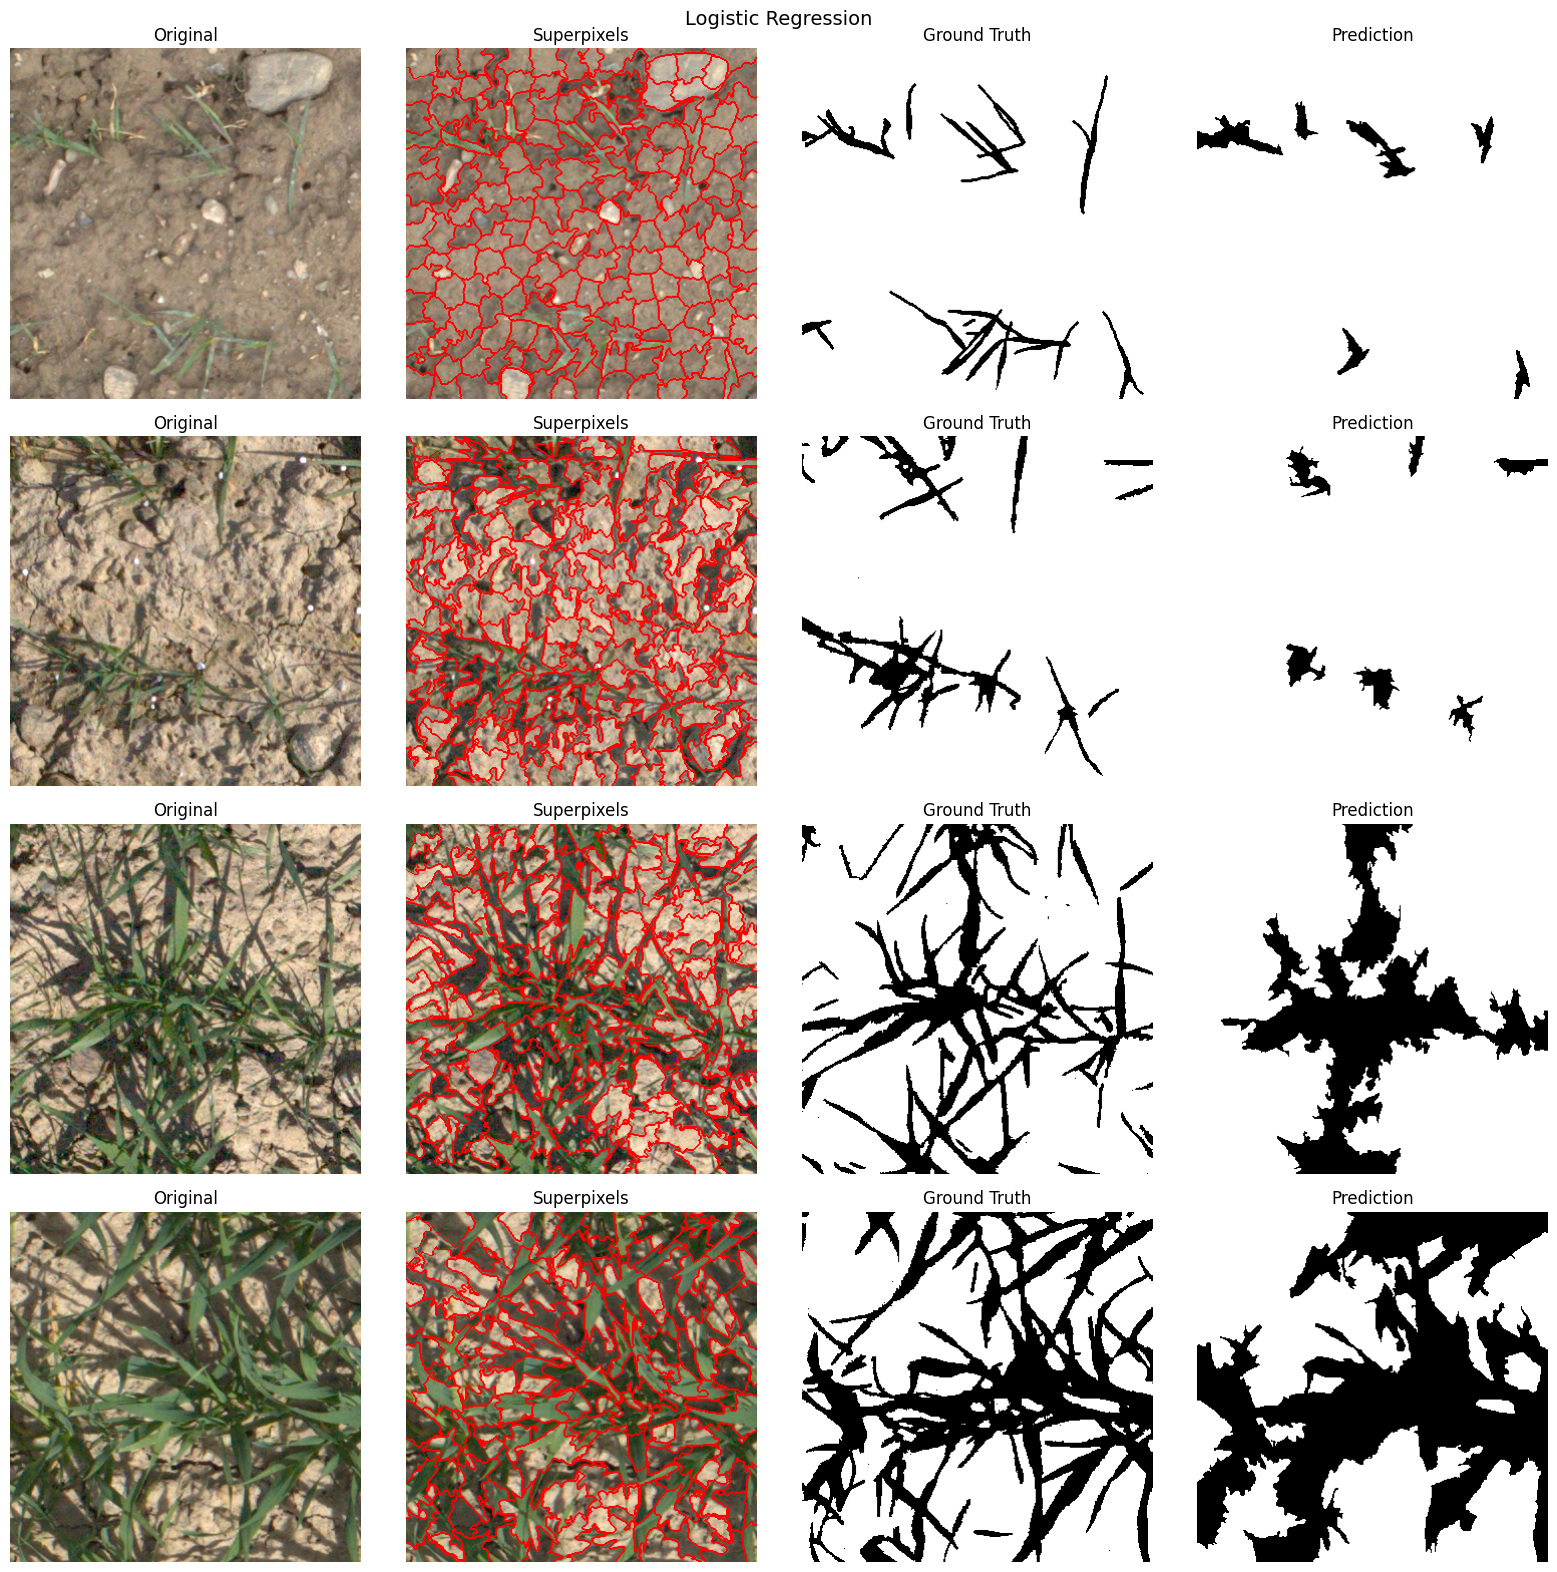

In [16]:
# Visualize results
def visualize_results(images, gt_masks, pred_masks, seg_list, title, num_samples=4):
    n = min(num_samples, len(images))
    fig, axes = plt.subplots(n, 4, figsize=(16, 4 * n))
    fig.suptitle(title, fontsize=14)
    titles = ["Original", "Superpixels", "Ground Truth", "Prediction"]
    for i in range(n):
        axes[i, 0].imshow(images[i])
        axes[i, 1].imshow(mark_boundaries(images[i], seg_list[i], color=(1, 0, 0)))
        axes[i, 2].imshow(gt_masks[i], cmap="gray")
        axes[i, 3].imshow(pred_masks[i], cmap="gray")
        for j, ax in enumerate(axes[i]):
            ax.set_title(titles[j])
            ax.axis("off")
    plt.tight_layout()
    plt.show()

visualize_results(test_imgs, test_masks, lr_pred, lr_seg, "Logistic Regression")

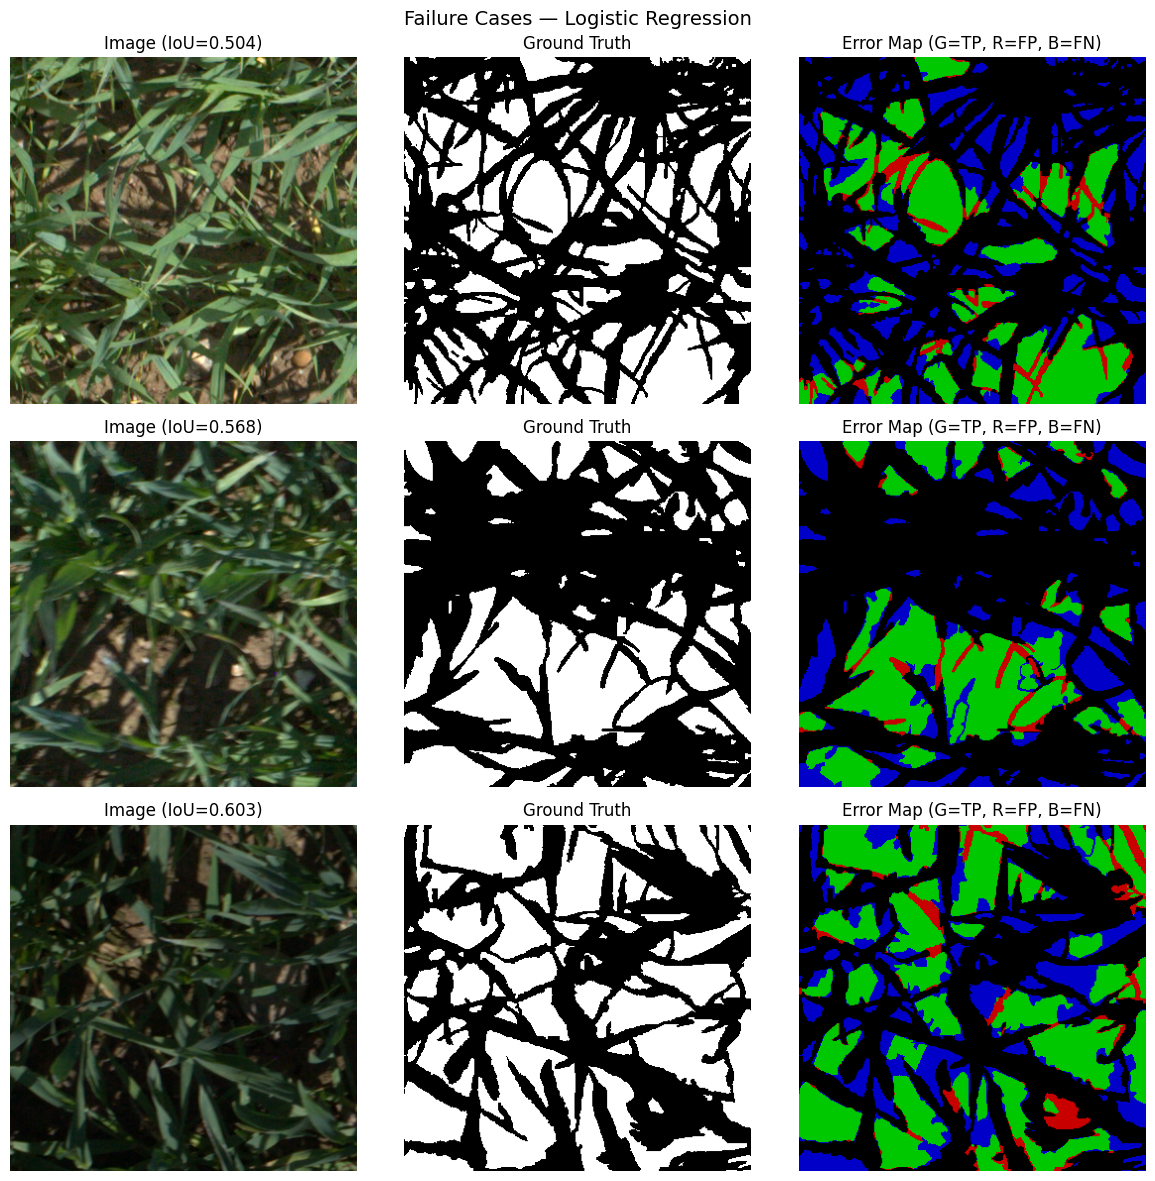

In [17]:
# Failure case analysis
def visualize_failure_cases(images, gt_masks, pred_masks, ious, title, num_cases=3):
    sorted_idx = np.argsort(ious)[:num_cases]
    fig, axes = plt.subplots(num_cases, 3, figsize=(12, 4 * num_cases))
    if num_cases == 1:
        axes = axes[np.newaxis, :]
    fig.suptitle(title, fontsize=14)
    for row, idx in enumerate(sorted_idx):
        axes[row, 0].imshow(images[idx])
        axes[row, 0].set_title(f"Image (IoU={ious[idx]:.3f})")
        axes[row, 1].imshow(gt_masks[idx], cmap="gray")
        axes[row, 1].set_title("Ground Truth")
        h, w = gt_masks[idx].shape
        overlay = np.zeros((h, w, 3), dtype=np.uint8)
        overlay[np.logical_and(pred_masks[idx] == 1, gt_masks[idx] == 1)] = [0, 200, 0]
        overlay[np.logical_and(pred_masks[idx] == 1, gt_masks[idx] == 0)] = [200, 0, 0]
        overlay[np.logical_and(pred_masks[idx] == 0, gt_masks[idx] == 1)] = [0, 0, 200]
        axes[row, 2].imshow(overlay)
        axes[row, 2].set_title("Error Map (G=TP, R=FP, B=FN)")
        for ax in axes[row]: ax.axis("off")
    plt.tight_layout()
    plt.show()

visualize_failure_cases(test_imgs, test_masks, lr_pred, lr_metrics["Per-image IoU"], "Failure Cases — Logistic Regression")

Top 5 features by coefficient magnitude:
  1. a_mean: 6.2372
  2. V_std: 2.5790
  3. V_mean: 1.7415
  4. B_std: 1.7248
  5. L_std: 1.1459


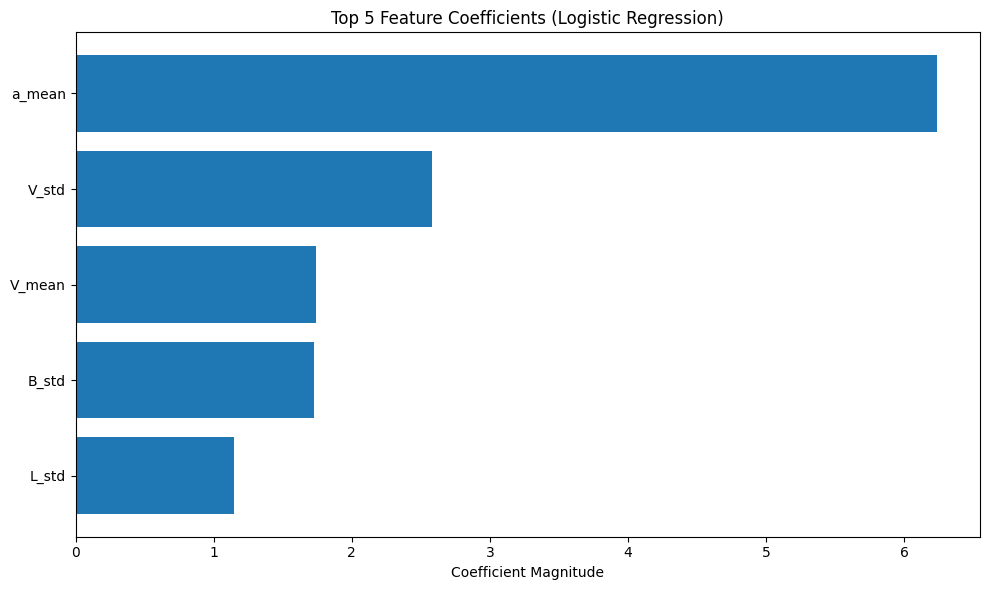

In [18]:
# Feature coefficient analysis
feature_names = (
    ["R_mean", "G_mean", "B_mean", "R_std", "G_std", "B_std"] +
    ["H_mean", "S_mean", "V_mean", "H_std", "S_std", "V_std"] +
    ["L_mean", "a_mean", "b_mean", "L_std", "a_std", "b_std"] +
    ["ExG", "ExR", "ExGR", "CIVE", "VEG"] +
    [f"LBP_{i}" for i in range(10)] +
    ["centroid_x", "centroid_y"]
)

# Absolute coefficient = contribution strength
coefs = np.abs(lr.coef_[0])
sorted_idx = np.argsort(coefs)[::-1]

print("Top 5 features by coefficient magnitude:")
for rank, idx in enumerate(sorted_idx[:5]):
    print(f"  {rank+1}. {feature_names[idx]}: {coefs[idx]:.4f}")

fig, ax = plt.subplots(figsize=(10, 6))
top_n = 5
top_idx = sorted_idx[:top_n]
ax.barh(range(top_n), coefs[top_idx][::-1])
ax.set_yticks(range(top_n))
ax.set_yticklabels([feature_names[i] for i in top_idx[::-1]])
ax.set_xlabel("Coefficient Magnitude")
ax.set_title("Top 5 Feature Coefficients (Logistic Regression)")
plt.tight_layout()
plt.show()